# MTS 60m Model 1: untuned baseline and manual feature review

Two independent task runs (GLD965/GLD9999), with dependent market evidence. No candidates are deleted.
The primary estimator uses the predefined 23-feature core. A second, clearly labeled all-313-feature
diagnostic Elastic Net provides wider permutation results. No hyperparameter search is performed.

Install `research/mts_gold/requirements-model1.txt` first. This notebook runs offline against the saved
all-date baseline tables, writes the Excel and Markdown/DOCX summaries, and retains detailed CSVs.
Six expanding chronological folds use >=30 observed embargo bars. These are development folds;
there is no new untouched final test period after inspecting these results.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'research/mts_gold/code').is_dir())
sys.path.insert(0, str(repo / 'research/mts_gold/code'))
from model1_baseline import CONFIG, FOLDS, run_experiment, sha
baseline = repo / 'research/mts_gold/training_artifacts/_training_baseline'
manifest = json.loads((baseline / 'manifest.json').read_text())
display(pd.DataFrame([{k: item[k] for k in ['symbol', 'file', 'rows', 'valid_labels', 'numeric_candidates']}
                      for item in manifest['outputs']]))
display(pd.DataFrame(CONFIG.items(), columns=['setting', 'value']))

,symbol,file,rows,valid_labels,numeric_candidates
0,GLD965,baseline_60m_GLD965.csv.gz,10338,9830,313
1,GLD9999,baseline_60m_GLD9999.csv.gz,10162,9633,313


,setting,value
0,alpha,1.000000e-02
1,l1_ratio,5.000000e-01
2,max_iter,1.000000e+04
3,tol,1.000000e-05
4,half_life,3.000000e+01
5,embargo_min_bars,3.000000e+01
6,null_flag_threshold,2.000000e-01
7,vif_warning_threshold,5.000000e+00
8,vif_severe_threshold,1.000000e+01
9,varclus_maxeigval2,1.000000e+00


## Labels, features and preprocessing

For each fold, initialize EWMA variance from the mean squared **training** hourly return; keep half-life=30.
The fitted label is `clip(next_log_return / sigma_t, -5, 5)`, not the precomputed causal-reference label.
Fold preprocessing keeps every supplied column: train median imputation (zero for all-null columns),
then training-only StandardScaler. Null flags and zero variance do not trigger model-input deletion.

The zero predictor is the benchmark. The Elastic Net settings are fixed above. Model 2 is not fitted;
any price forecast shown here uses trailing sigma for diagnostic rescaling only.

In [2]:
for task in manifest['outputs']:
    assert len(task['groups']['model1_core']) <= 25
    print(task['symbol'], 'core features:')
    display(pd.DataFrame({'feature': task['groups']['model1_core']}))
display(pd.DataFrame(FOLDS, columns=['fold', 'train_end_Bangkok', 'validation_start_Bangkok', 'validation_end_Bangkok']))

GLD965 core features:


,feature
0,own_log_return_shift1
1,own_log_return_shift5
2,own_log_return_shift30
3,cross_log_return_shift1
4,cross_log_return_shift5
5,cross_log_return_shift30
6,xauusd_log_return_shift1
7,xauusd_log_return_shift5
8,xauusd_log_return_shift30
9,btc_log_return_shift1


GLD9999 core features:


,feature
0,own_log_return_shift1
1,own_log_return_shift5
2,own_log_return_shift30
3,cross_log_return_shift1
4,cross_log_return_shift5
5,cross_log_return_shift30
6,xauusd_log_return_shift1
7,xauusd_log_return_shift5
8,xauusd_log_return_shift30
9,btc_log_return_shift1


,fold,train_end_Bangkok,validation_start_Bangkok,validation_end_Bangkok
0,F1,2025-07-01,2025-07-08,2025-10-01
1,F2,2025-10-01,2025-10-08,2026-01-01
2,F3,2026-01-01,2026-01-08,2026-04-01
3,F4,2026-04-01,2026-04-08,2026-07-01
4,F5,2026-07-01,2026-07-08,2026-10-01
5,F6,2026-10-01,2026-10-08,2026-11-08


## Train the fixed baselines and export the audit

This cell performs all fold fits, train-only diagnostics, validation block permutation,
paired block bootstrap, and exports. It can take several minutes. Progress is written to
`model1_results/progress.log`. Re-running replaces derived results only; candidate tables remain unchanged.

In [3]:
results = run_experiment(baseline)
display(results['fold_schedule'])
display(results['cv_summary'])
for task in manifest['outputs']:
    assert sha(baseline / task['file']) == task['sha256']
print('Input hashes unchanged. No features removed.')

,symbol,fold,train_start,train_end,validation_start,validation_end,training_sigma_median,ewma_seed_variance,half_life,embargo_context_bars,train_rows,validation_rows
0,GLD965,F1,2025-01-01T00:00:00+07:00,2025-07-01T00:00:00+07:00,2025-07-08T00:00:00+07:00,2025-10-01T00:00:00+07:00,0.001426,0.000003,30,107,2603,1251
1,GLD965,F2,2025-01-01T00:00:00+07:00,2025-10-01T00:00:00+07:00,2025-10-08T00:00:00+07:00,2026-01-01T00:00:00+07:00,0.001331,0.000003,30,108,3957,1234
2,GLD965,F3,2025-01-01T00:00:00+07:00,2026-01-01T00:00:00+07:00,2026-01-08T00:00:00+07:00,2026-04-01T00:00:00+07:00,0.001465,0.000004,30,87,5294,1218
3,GLD965,F4,2025-01-01T00:00:00+07:00,2026-04-01T00:00:00+07:00,2026-04-08T00:00:00+07:00,2026-07-01T00:00:00+07:00,0.001675,0.000006,30,87,6594,1232
4,GLD965,F5,2025-01-01T00:00:00+07:00,2026-07-01T00:00:00+07:00,2026-07-08T00:00:00+07:00,2026-10-01T00:00:00+07:00,0.001855,0.000006,30,105,7910,1255
5,GLD965,F6,2025-01-01T00:00:00+07:00,2026-10-01T00:00:00+07:00,2026-10-08T00:00:00+07:00,2026-11-08T00:00:00+07:00,0.001981,0.000006,30,106,9266,463
6,GLD9999,F1,2025-01-01T00:00:00+07:00,2025-07-01T00:00:00+07:00,2025-07-08T00:00:00+07:00,2025-10-01T00:00:00+07:00,0.001446,0.000003,30,105,2488,1183
7,GLD9999,F2,2025-01-01T00:00:00+07:00,2025-10-01T00:00:00+07:00,2025-10-08T00:00:00+07:00,2026-01-01T00:00:00+07:00,0.001330,0.000003,30,108,3772,1222
8,GLD9999,F3,2025-01-01T00:00:00+07:00,2026-01-01T00:00:00+07:00,2026-01-08T00:00:00+07:00,2026-04-01T00:00:00+07:00,0.001456,0.000003,30,87,5097,1219
9,GLD9999,F4,2025-01-01T00:00:00+07:00,2026-04-01T00:00:00+07:00,2026-04-08T00:00:00+07:00,2026-07-01T00:00:00+07:00,0.001668,0.000006,30,87,6398,1232


,symbol,model,rows,mse_z,mae_z,zero_baseline_mse,r2_vs_zero,mse_improvement_vs_zero,directional_rows,directional_coverage,directional_accuracy,mse_improvement_ci_low,mse_improvement_ci_high,r2_ci_low,r2_ci_high,acceptance_ci_positive,bootstrap_method
0,GLD965,elasticnet_all313_diagnostic,6653,1200.529350,7.688036,1.059133,-1132.501586,-1199.470217,6072,0.912671,0.500165,-2328.366931,-448.863410,-2298.946657,-420.314342,False,"paired circular 30-observation blocks, stratif..."
1,GLD965,elasticnet_core23,6653,1.058926,0.741118,1.059133,0.000196,0.000207,3107,0.467007,0.532990,-0.005546,0.006036,-0.005241,0.005799,False,"paired circular 30-observation blocks, stratif..."
2,GLD965,zero,6653,1.059133,0.742101,1.059133,0.000000,0.000000,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,GLD9999,elasticnet_all313_diagnostic,6573,458.754315,5.214117,1.059487,-431.996480,-457.694828,5958,0.906435,0.500839,-940.429114,-172.362680,-889.049178,-164.010336,False,"paired circular 30-observation blocks, stratif..."
4,GLD9999,elasticnet_core23,6573,1.060398,0.741266,1.059487,-0.000859,-0.000910,3096,0.471018,0.526163,-0.006587,0.004607,-0.006154,0.004420,False,"paired circular 30-observation blocks, stratif..."
5,GLD9999,zero,6573,1.059487,0.741165,1.059487,0.000000,0.000000,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Input hashes unchanged. No features removed.


## 1–2. Null rate and zero variance

`null_ge_20pct` flags >=20%, including exactly20%. All-null variance is undefined;
zero variance means one observed distinct value. All diagnostics below use fold-training rows only.

In [4]:
flags = results['null_variance'].groupby(['symbol', 'fold']).agg(
    null_ge_20pct=('null_ge_20pct', 'sum'), all_null=('all_null', 'sum'),
    zero_variance=('zero_variance', 'sum'))
display(flags)
display(results['null_variance'].query("fold == 'F6' and symbol == 'GLD965'").sort_values('null_rate', ascending=False).head(15))

null_ge_20pct  all_null  zero_variance
symbol  fold                                        
GLD965  F1               80        45              8
        F2               47        45              8
        F3               47        30             12
        F4               47         8             17
        F5               47         0             19
        F6               47         0             19
GLD9999 F1               80        45              8
        F2               47        45              8
        F3               47        30             12
        F4               47         8             17
        F5               47         0             19
        F6               47         0             19

,feature,train_rows,observed_count,null_count,null_rate,null_ge_20pct,unique_count,sample_variance,zero_variance,all_null,action,symbol,fold
1803,gap_log_return,9266,476,8790,0.948629,True,473,1.968322e-05,False,False,REVIEW_ONLY_NO_DROP,GLD965,F6
1635,xautusdt_1d_close_lag30,9266,2313,6953,0.750378,True,113,6.376036e+04,False,False,REVIEW_ONLY_NO_DROP,GLD965,F6
1636,xautusdt_1d_return_lag30,9266,2313,6953,0.750378,True,113,4.146408e-03,False,False,REVIEW_ONLY_NO_DROP,GLD965,F6
1637,xautusdt_1d_elapsed_min_lag30,9266,2313,6953,0.750378,True,1,0.000000e+00,True,False,REVIEW_ONLY_NO_DROP,GLD965,F6
1641,xautusdt_1d_volume_lag30,9266,2313,6953,0.750378,True,113,4.303187e+08,False,False,REVIEW_ONLY_NO_DROP,GLD965,F6
1633,xautusdt_1d_return_lag5,9266,2646,6620,0.714440,True,129,5.710530e-04,False,False,REVIEW_ONLY_NO_DROP,GLD965,F6
1640,xautusdt_1d_volume_lag5,9266,2646,6620,0.714440,True,129,4.050540e+08,False,False,REVIEW_ONLY_NO_DROP,GLD965,F6
1632,xautusdt_1d_close_lag5,9266,2646,6620,0.714440,True,129,5.866318e+04,False,False,REVIEW_ONLY_NO_DROP,GLD965,F6
1634,xautusdt_1d_elapsed_min_lag5,9266,2646,6620,0.714440,True,1,0.000000e+00,True,False,REVIEW_ONLY_NO_DROP,GLD965,F6
1620,xautusdt_60m_close_lag30,9266,2707,6559,0.707857,True,2625,5.613791e+04,False,False,REVIEW_ONLY_NO_DROP,GLD965,F6


## 3. VIF for multicollinearity

VIF is reported for both core and full candidate scopes using training-imputed values.
Undefined constant/all-null fields stay in the export. `inf` marks numerical collinearity
at the recorded eigenvalue tolerance. No recursive VIF-based deletion is performed.

In [5]:
display(results['vif'].groupby(['symbol', 'fold', 'scope', 'vif_status']).size().unstack(fill_value=0))
display(results['vif'].query("scope == 'core23' and symbol == 'GLD965' and fold == 'F6'").sort_values('vif', ascending=False))

vif_status                   all_null  finite  numerical_collinearity  \
symbol  fold scope                                                      
GLD965  F1   all_candidates        45     219                      41   
             core23                 0      23                       0   
        F2   all_candidates        45     219                      41   
             core23                 0      23                       0   
        F3   all_candidates        30     233                      38   
             core23                 0      23                       0   
        F4   all_candidates         8     247                      41   
             core23                 0      23                       0   
        F5   all_candidates         0     257                      37   
             core23                 0      23                       0   
        F6   all_candidates         0     257                      37   
             core23                 0      23                       0   
GLD9999 F1   all_candidates        45     219                      41   
             core23                 0      23                       0   
        F2   all_candidates        45     219                      41   
             core23                 0      23                       0   
        F3   all_candidates        30     233                      38   
             core23                 0      23                       0   
        F4   all_candidates         8     247                      41   
             core23                 0      23                       0   
        F5   all_candidates         0     257                      37   
             core23                 0      23                       0   
        F6   all_candidates         0     257                      37   
             core23                 0      23                       0   

vif_status                   zero_variance  
symbol  fold scope                          
GLD965  F1   all_candidates              8  
             core23                      0  
        F2   all_candidates              8  
             core23                      0  
        F3   all_candidates             12  
             core23                      0  
        F4   all_candidates             17  
             core23                      0  
        F5   all_candidates             19  
             core23                      0  
        F6   all_candidates             19  
             core23                      0  
GLD9999 F1   all_candidates              8  
             core23                      0  
        F2   all_candidates              8  
             core23                      0  
        F3   all_candidates             12  
             core23                      0  
        F4   all_candidates             17  
             core23                      0  
        F5   all_candidates             19  
             core23                      0  
        F6   all_candidates             19  
             core23                      0

,feature,vif,vif_status,null_space_loading,correlation_rank,estimable_column_count,eigenvalue_cutoff,vif_ge_5,vif_ge_10,symbol,fold,scope
2015,cross_log_return,43.482304,finite,0.0,23,23,3.044862e-10,True,True,GLD965,F6,core23
2014,own_log_return,43.450952,finite,0.0,23,23,3.044862e-10,True,True,GLD965,F6,core23
1993,own_log_return_shift1,35.019474,finite,0.0,23,23,3.044862e-10,True,True,GLD965,F6,core23
1996,cross_log_return_shift1,34.022135,finite,0.0,23,23,3.044862e-10,True,True,GLD965,F6,core23
1994,own_log_return_shift5,33.480470,finite,0.0,23,23,3.044862e-10,True,True,GLD965,F6,core23
1997,cross_log_return_shift5,33.073108,finite,0.0,23,23,3.044862e-10,True,True,GLD965,F6,core23
1995,own_log_return_shift30,32.667086,finite,0.0,23,23,3.044862e-10,True,True,GLD965,F6,core23
1998,cross_log_return_shift30,32.236585,finite,0.0,23,23,3.044862e-10,True,True,GLD965,F6,core23
1999,xauusd_log_return_shift1,7.761398,finite,0.0,23,23,3.044862e-10,True,False,GLD965,F6,core23
2000,xauusd_log_return_shift5,6.786331,finite,0.0,23,23,3.044862e-10,True,False,GLD965,F6,core23


## 4. VARCLUS candidate representatives

PCA/quartimax variable clustering splits until the second eigenvalue is <=1.
R²-own, R²-nearest-other-cluster and the R² ratio are exported. A low-ratio representative
is only a suggestion. Cluster IDs are local to each fold, not stable labels across time.

In [6]:
display(results['varclus_clusters'].groupby(['symbol', 'fold']).size().rename('cluster_count'))
display(results['varclus_features'].query("fold == 'F6' and symbol == 'GLD965' and representative_suggestion").sort_values('r2_ratio').head(20))

symbol   fold
GLD965   F1      51
         F2      49
         F3      55
         F4      58
         F5      59
         F6      65
GLD9999  F1      50
         F2      52
         F3      53
         F4      59
         F5      64
         F6      65
Name: cluster_count, dtype: int64

,feature,cluster_status,cluster,r2_own,r2_next_cluster,r2_ratio,representative_suggestion,symbol,fold
1633,xautusdt_1d_return_lag5,clustered,56.0,1.000000,0.098005,0.000000e+00,True,GLD965,F6
1618,xautusdt_60m_return_lag5,clustered,62.0,1.000000,0.277817,0.000000e+00,True,GLD965,F6
1774,wti_oil_1d_return_lag1,clustered,63.0,1.000000,0.171394,0.000000e+00,True,GLD965,F6
1822,btc_log_return_shift5,clustered,64.0,1.000000,0.025952,0.000000e+00,True,GLD965,F6
1823,btc_log_return_shift30,clustered,50.0,1.000000,0.027034,0.000000e+00,True,GLD965,F6
1793,xauusdt_60m_return_lag30,clustered,59.0,1.000000,0.546731,0.000000e+00,True,GLD965,F6
1752,vix_1d_return_lag1,clustered,57.0,1.000000,0.698347,0.000000e+00,True,GLD965,F6
1872,return_skew30,clustered,51.0,1.000000,0.266061,0.000000e+00,True,GLD965,F6
1612,mts_xauusd_60m_age_minutes,clustered,42.0,1.000000,0.006035,2.233927e-16,True,GLD965,F6
1640,xautusdt_1d_volume_lag5,clustered,58.0,1.000000,0.033796,2.298112e-16,True,GLD965,F6


## 5. Validation permutation importance

Importance is validation MSE increase after 30-observation block permutation (20 repeats).
Positive is useful for this fitted estimator; negative/zero is not proof of universal irrelevance.
Collinear substitutes can mask each other's importance. Repeat p05/p95 describe dispersion,
not inferential confidence intervals. Review both the compact core and wider diagnostic model.

GLD965 elasticnet_core23


,symbol,model,feature,weighted_mean_importance,positive_folds,folds,min_fold_importance,max_fold_importance,zero_coefficient_folds
330,GLD965,elasticnet_core23,session_open_flag,0.008804,6,6,0.001159,0.013458,0
322,GLD965,elasticnet_core23,fair_return_gap_window30,0.001944,6,6,0.000676,0.004726,0
323,GLD965,elasticnet_core23,fair_return_gap_window5,0.001837,6,6,0.000170,0.003711,0
326,GLD965,elasticnet_core23,own_log_return,0.001427,5,6,-0.000053,0.003401,0
324,GLD965,elasticnet_core23,hour_cos,0.000823,5,6,0.000000,0.001715,1
321,GLD965,elasticnet_core23,fair_return_gap_window1,0.000687,4,6,-0.000296,0.002165,0
320,GLD965,elasticnet_core23,elapsed_minutes_previous_bar,0.000417,1,6,-0.002100,0.004484,2
327,GLD965,elasticnet_core23,own_log_return_shift1,0.000197,2,6,-0.001025,0.001653,0
331,GLD965,elasticnet_core23,weekday_cos,0.000154,3,6,-0.001895,0.004513,0
315,GLD965,elasticnet_core23,btc_log_return_shift5,0.000113,4,6,-0.000974,0.001848,0


GLD9999 elasticnet_core23


,symbol,model,feature,weighted_mean_importance,positive_folds,folds,min_fold_importance,max_fold_importance,zero_coefficient_folds
666,GLD9999,elasticnet_core23,session_open_flag,0.004647,5,6,-0.000486,0.008224,0
658,GLD9999,elasticnet_core23,fair_return_gap_window30,0.002096,6,6,0.000287,0.005209,0
659,GLD9999,elasticnet_core23,fair_return_gap_window5,0.001766,6,6,0.000312,0.003446,0
652,GLD9999,elasticnet_core23,cross_log_return,0.001187,5,6,-0.000419,0.003387,0
657,GLD9999,elasticnet_core23,fair_return_gap_window1,0.000384,2,6,-0.000323,0.001402,2
660,GLD9999,elasticnet_core23,hour_cos,0.000339,5,6,0.000000,0.000970,1
663,GLD9999,elasticnet_core23,own_log_return_shift1,0.000085,1,6,-0.000763,0.001051,2
671,GLD9999,elasticnet_core23,xauusd_log_return_shift5,0.000052,1,6,-0.000890,0.001585,3
667,GLD9999,elasticnet_core23,weekday_cos,0.000002,2,6,-0.001448,0.003420,0
653,GLD9999,elasticnet_core23,cross_log_return_shift1,0.000000,0,6,0.000000,0.000000,6


GLD965 elasticnet_all313_diagnostic


,symbol,model,feature,weighted_mean_importance,positive_folds,folds,min_fold_importance,max_fold_importance,zero_coefficient_folds
311,GLD965,elasticnet_all313_diagnostic,xauusdt_60m_volume_lag30,84.417809,3,6,-0.000261,461.099604,2
312,GLD965,elasticnet_all313_diagnostic,xauusdt_60m_volume_lag5,39.078630,2,6,-0.000192,213.455772,3
310,GLD965,elasticnet_all313_diagnostic,xauusdt_60m_volume_lag1,34.920376,1,6,0.000000,190.743235,5
299,GLD965,elasticnet_all313_diagnostic,xauusdt_60m_close,1.227322,1,6,0.000000,6.703916,5
246,GLD965,elasticnet_all313_diagnostic,vix_1d_elapsed_min_lag30,0.405071,2,6,0.000000,2.207702,3
293,GLD965,elasticnet_all313_diagnostic,xautusdt_60m_volume_lag5,0.241744,2,6,-0.000067,1.305468,3
294,GLD965,elasticnet_all313_diagnostic,xauusd_log_return,0.178814,3,6,-0.000304,0.967449,2
265,GLD965,elasticnet_all313_diagnostic,xautusdt_1d_close,0.157497,1,6,0.000000,0.850510,5
167,GLD965,elasticnet_all313_diagnostic,return_var7,0.122837,1,6,0.000000,0.670963,5
239,GLD965,elasticnet_all313_diagnostic,usdthb_1d_return_lag5,0.111467,2,6,0.000000,0.607405,4


GLD9999 elasticnet_all313_diagnostic


,symbol,model,feature,weighted_mean_importance,positive_folds,folds,min_fold_importance,max_fold_importance,zero_coefficient_folds
647,GLD9999,elasticnet_all313_diagnostic,xauusdt_60m_volume_lag30,35.994798,3,6,-0.000287,194.080173,2
646,GLD9999,elasticnet_all313_diagnostic,xauusdt_60m_volume_lag1,16.310801,2,6,0.000000,87.947540,4
648,GLD9999,elasticnet_all313_diagnostic,xauusdt_60m_volume_lag5,14.690570,2,6,-0.000451,79.213067,3
635,GLD9999,elasticnet_all313_diagnostic,xauusdt_60m_close,0.779067,1,6,0.000000,4.200827,5
582,GLD9999,elasticnet_all313_diagnostic,vix_1d_elapsed_min_lag30,0.335789,2,6,-0.000658,1.805230,2
629,GLD9999,elasticnet_all313_diagnostic,xautusdt_60m_volume_lag5,0.284464,2,6,-0.000072,1.517695,3
601,GLD9999,elasticnet_all313_diagnostic,xautusdt_1d_close,0.177314,1,6,0.000000,0.946008,5
630,GLD9999,elasticnet_all313_diagnostic,xauusd_log_return,0.119359,2,6,-0.003700,0.632660,2
628,GLD9999,elasticnet_all313_diagnostic,xautusdt_60m_volume_lag30,0.102598,2,6,-0.000400,0.547396,3
619,GLD9999,elasticnet_all313_diagnostic,xautusdt_60m_close_lag5,0.088261,1,6,0.000000,0.470892,5


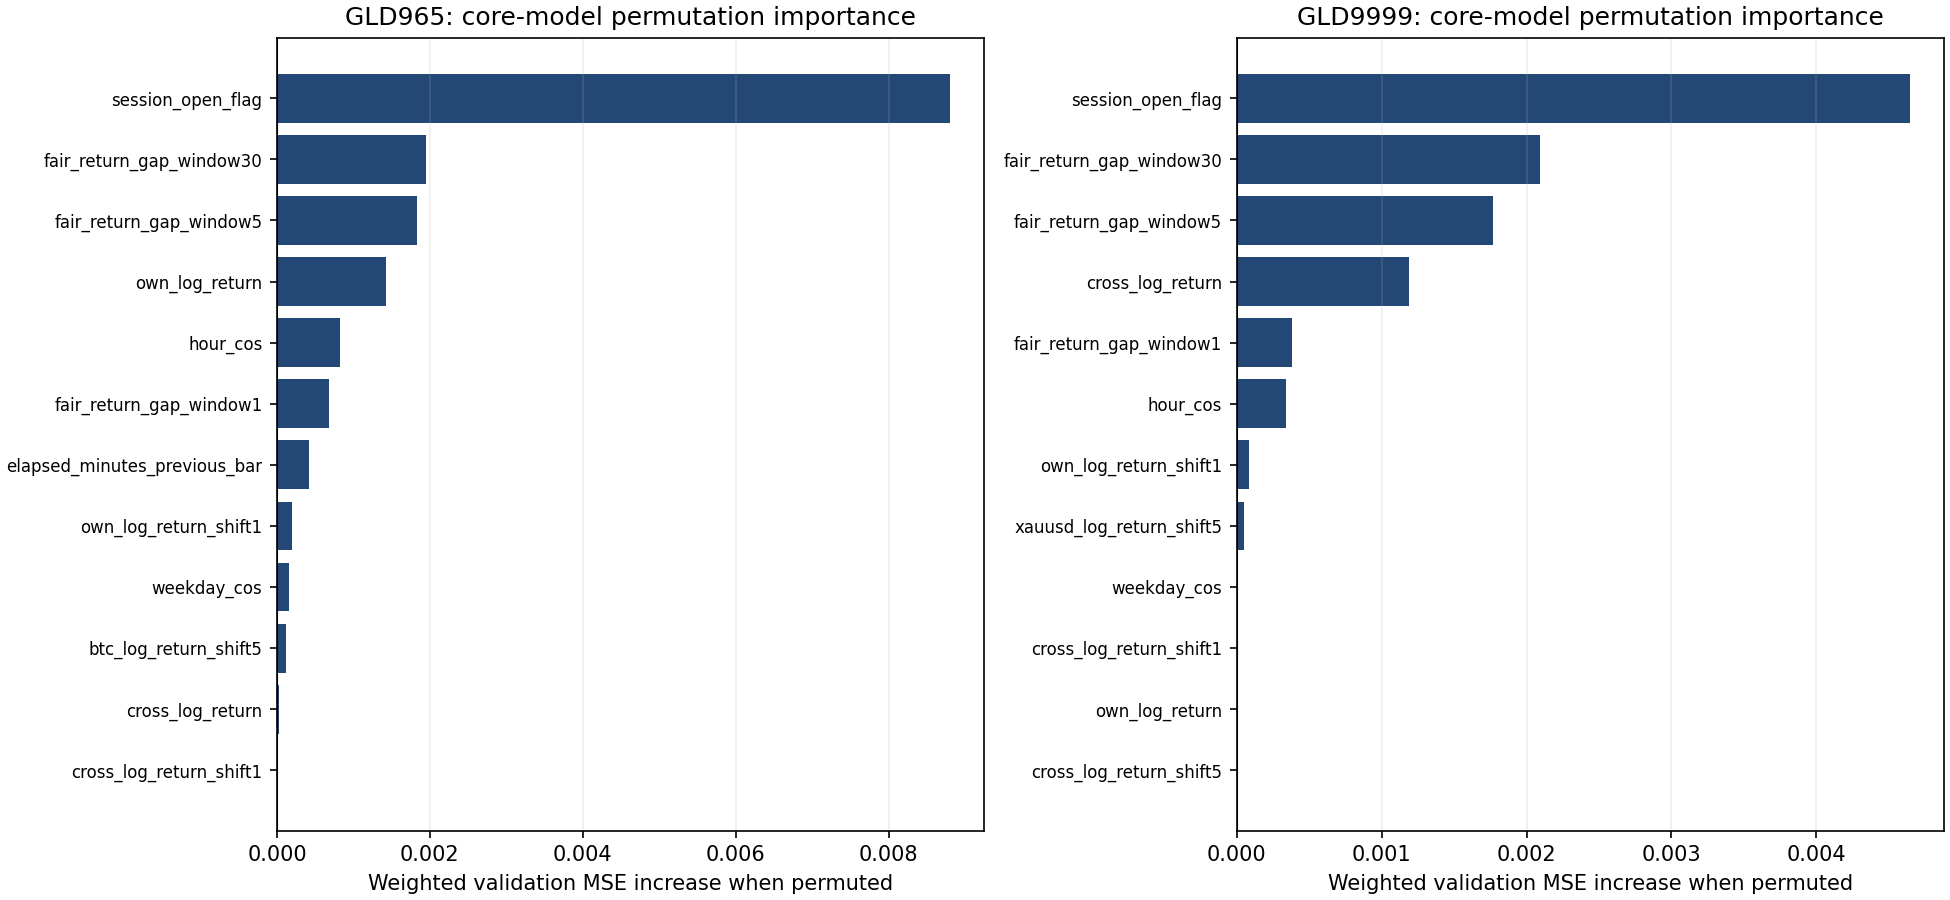

In [7]:
for model in ['elasticnet_core23', 'elasticnet_all313_diagnostic']:
    for symbol in ['GLD965', 'GLD9999']:
        print(symbol, model)
        display(results['permutation_summary'].query('symbol == @symbol and model == @model').nlargest(10, 'weighted_mean_importance'))
display(Image(filename=str(baseline / 'model1_results/permutation_core.png')))

## Scores, acceptance and regime diagnostics

R² is measured against a zero forecast. Direction accuracy excludes |z_hat|<=0.05 and actual zeros;
coverage is reported. Accept a stage only if the paired 30-observation block-bootstrap 95% CI
for MSE improvement has lower bound >0. Regimes use the training median sigma of each fold.
Both purities are near-duplicates and should not be counted as independent tests.

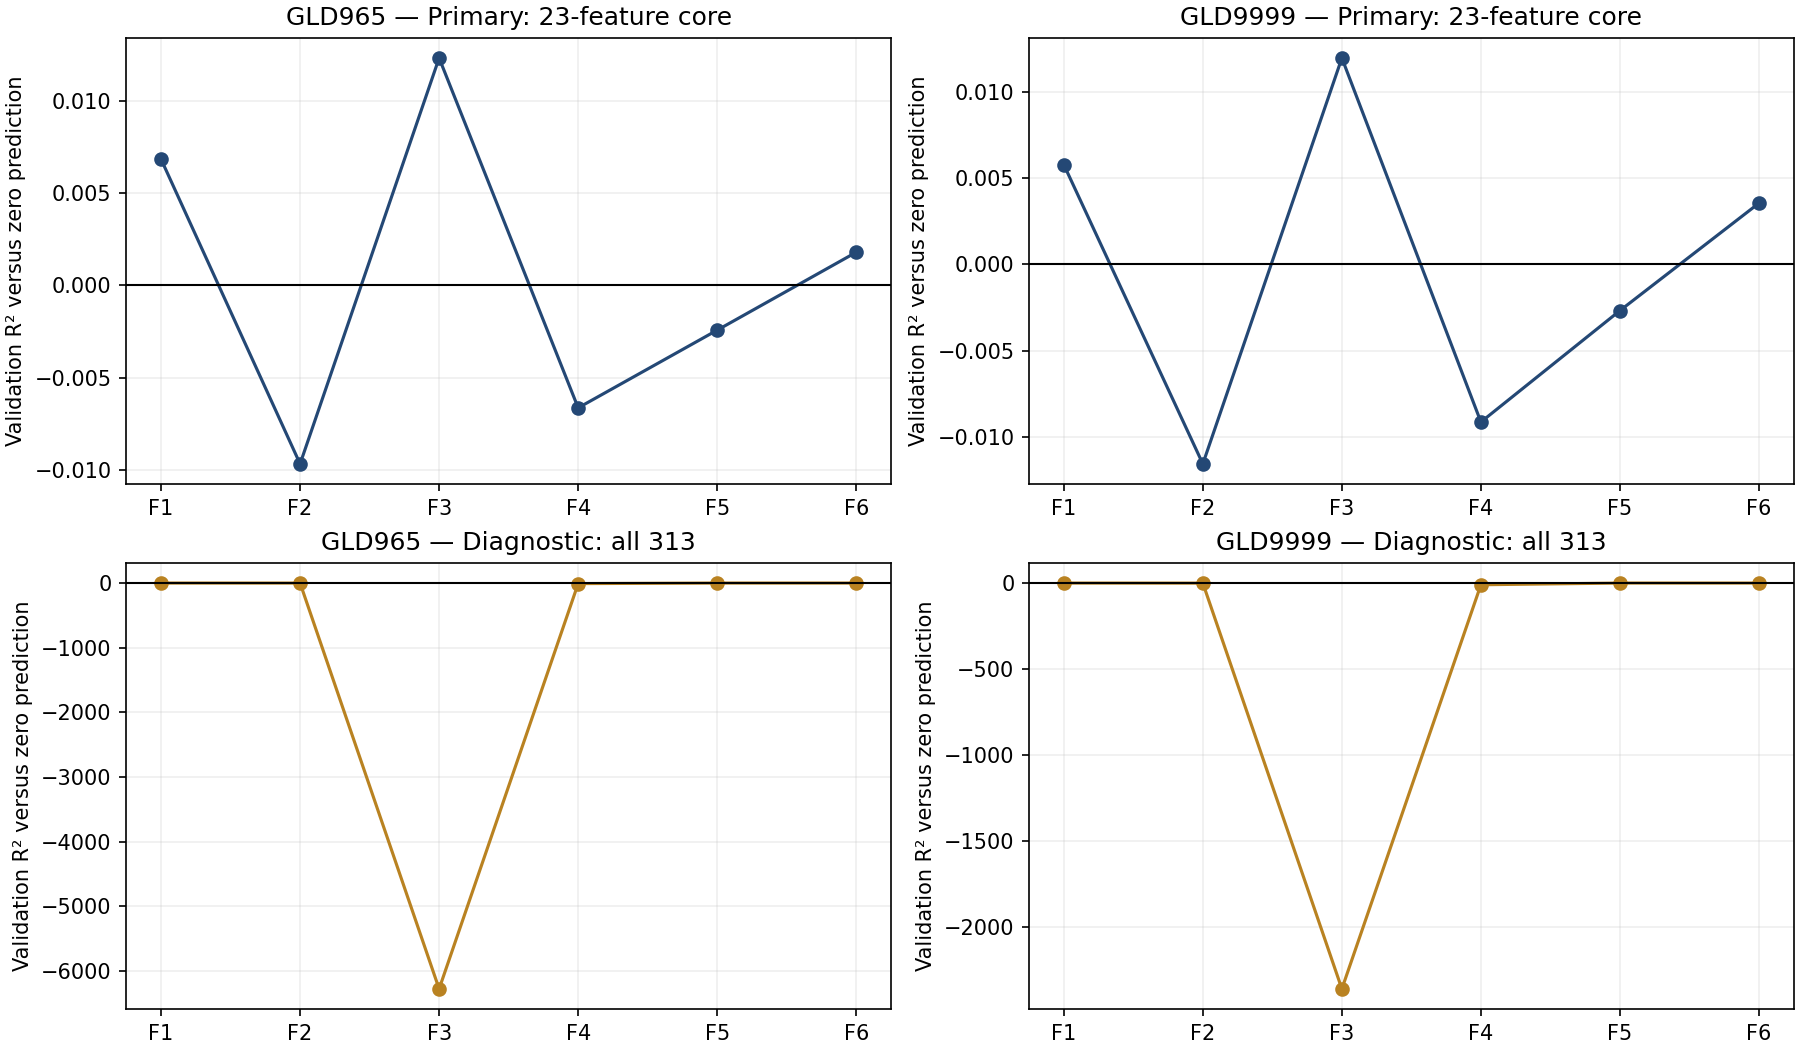

,symbol,model,volatility_regime,rows,mse_z,mae_z,zero_baseline_mse,r2_vs_zero,mse_improvement_vs_zero,directional_rows,directional_coverage,directional_accuracy
0,GLD965,elasticnet_all313_diagnostic,above_train_median,5186,1539.666381,9.606624,1.021558,-1506.175021,-1538.644823,4808,0.927111,0.499168
1,GLD965,elasticnet_all313_diagnostic,at_or_below_train_median,1467,1.644114,0.905625,1.191967,-0.379329,-0.452147,1264,0.861622,0.503956
2,GLD965,elasticnet_core23,above_train_median,5186,1.023756,0.723837,1.021558,-0.002152,-0.002198,2499,0.481874,0.532613
3,GLD965,elasticnet_core23,at_or_below_train_median,1467,1.183257,0.802209,1.191967,0.007308,0.008710,608,0.414451,0.534539
4,GLD965,zero,above_train_median,5186,1.021558,0.724192,1.021558,0.000000,0.000000,0,0.000000,NaN
5,GLD965,zero,at_or_below_train_median,1467,1.191967,0.805414,1.191967,0.000000,0.000000,0,0.000000,NaN
6,GLD9999,elasticnet_all313_diagnostic,above_train_median,5071,594.186171,6.496206,1.025358,-578.491247,-593.160813,4706,0.928022,0.501275
7,GLD9999,elasticnet_all313_diagnostic,at_or_below_train_median,1502,1.514008,0.885570,1.174713,-0.288832,-0.339295,1252,0.833555,0.499201
8,GLD9999,elasticnet_core23,above_train_median,5071,1.029118,0.725181,1.025358,-0.003666,-0.003759,2479,0.488858,0.527229
9,GLD9999,elasticnet_core23,at_or_below_train_median,1502,1.166004,0.795570,1.174713,0.007413,0.008708,617,0.410786,0.521880


,symbol,model,bangkok_hour,rows,mse_z,mae_z,zero_baseline_mse,r2_vs_zero,mse_improvement_vs_zero,directional_rows,directional_coverage,directional_accuracy
22,GLD965,elasticnet_core23,0,320,0.707811,0.621984,0.719219,0.015862,0.011408,136,0.425000,0.610294
23,GLD965,elasticnet_core23,1,318,1.038743,0.678761,1.037972,-0.000742,-0.000771,122,0.383648,0.540984
24,GLD965,elasticnet_core23,2,314,1.032346,0.708878,1.039544,0.006924,0.007198,127,0.404459,0.582677
25,GLD965,elasticnet_core23,3,312,0.951010,0.730890,0.958533,0.007849,0.007523,134,0.429487,0.567164
26,GLD965,elasticnet_core23,4,83,1.286660,0.836215,1.247629,-0.031285,-0.039032,45,0.542169,0.422222
27,GLD965,elasticnet_core23,7,180,1.074739,0.789056,1.101744,0.024512,0.027005,179,0.994444,0.586592
28,GLD965,elasticnet_core23,8,320,1.878579,1.068287,1.922785,0.022991,0.044206,203,0.634375,0.556650
29,GLD965,elasticnet_core23,9,320,1.194932,0.815125,1.195869,0.000783,0.000937,164,0.512500,0.524390
30,GLD965,elasticnet_core23,10,322,0.628877,0.605999,0.625703,-0.005073,-0.003174,149,0.462733,0.516779
31,GLD965,elasticnet_core23,11,322,0.518716,0.533880,0.514015,-0.009145,-0.004701,155,0.481366,0.535484


,symbol,fold,model,partition,features,rows,mse_z,mae_z,zero_baseline_mse,r2_vs_zero,mse_improvement_vs_zero,directional_rows,directional_coverage,directional_accuracy,iterations,dual_gap,converged,nonzero_coefficients
1,GLD965,F1,zero,validation,0,1251,1.088751,0.780728,1.088751,0.000000,0.000000,0,0.000000,NaN,0,0.000000e+00,True,0
3,GLD965,F1,elasticnet_core23,validation,23,1251,1.081294,0.777120,1.088751,0.006849,0.007457,639,0.510791,0.528951,51,2.836077e-07,True,17
5,GLD965,F1,elasticnet_all313_diagnostic,validation,313,1251,1.228713,0.837484,1.088751,-0.128552,-0.139962,1186,0.948042,0.484823,847,3.643273e-06,True,101
7,GLD965,F2,zero,validation,0,1234,1.095086,0.750165,1.095086,0.000000,0.000000,0,0.000000,NaN,0,0.000000e+00,True,0
9,GLD965,F2,elasticnet_core23,validation,23,1234,1.105686,0.750455,1.095086,-0.009680,-0.010600,761,0.616694,0.530880,31,2.564311e-08,True,17
11,GLD965,F2,elasticnet_all313_diagnostic,validation,313,1234,1.462396,0.891153,1.095086,-0.335416,-0.367310,1174,0.951378,0.510221,2146,8.775705e-07,True,99
13,GLD965,F3,zero,validation,0,1218,1.042281,0.703410,1.042281,0.000000,0.000000,0,0.000000,NaN,0,0.000000e+00,True,0
15,GLD965,F3,elasticnet_core23,validation,23,1218,1.029423,0.696192,1.042281,0.012336,0.012858,676,0.555008,0.562130,38,1.484133e-08,True,15
17,GLD965,F3,elasticnet_all313_diagnostic,validation,313,1218,6543.291189,36.682635,1.042281,-6276.856404,-6542.248907,1210,0.993432,0.485950,744,8.836835e-07,True,87
19,GLD965,F4,zero,validation,0,1232,1.023238,0.739548,1.023238,0.000000,0.000000,0,0.000000,NaN,0,0.000000e+00,True,0


In [2]:
display(Image(filename=str(baseline / 'model1_results/fold_scores.png')))
display(results['regime_metrics'])
display(results['hour_metrics'].query("model == 'elasticnet_core23'"))
display(results['fold_metrics'].query("partition == 'validation'"))

## Manual selection and saved deliverables

Fill `manual_decision` and `manual_notes` in Excel's `manual_review` sheet. Review recurring
missingness, source timing, redundancy and fold stability before choosing features. Any later
selection using these validation results needs fresh or nested chronological evaluation.
The Markdown/DOCX summary explains the findings and proposed next development steps.

In [9]:
display(results['manual_review'].head(15))
display(pd.DataFrame({'deliverable': ['Model1_Baseline_Review.xlsx', 'Model1_Baseline_Summary.md',
                                     'Model1_Baseline_Summary.docx'],
                      'exists': [(baseline / p).exists() for p in ['Model1_Baseline_Review.xlsx',
                                  'Model1_Baseline_Summary.md', 'Model1_Baseline_Summary.docx']]}))
audit = json.loads((baseline / 'model1_results/run_manifest.json').read_text())
display(pd.DataFrame(audit['versions'].items(), columns=['package', 'version']))

,symbol,feature,folds,null_rate_min,null_rate_max,null_flag_folds,all_null_folds,zero_variance_folds,vif_infinite_folds,vif_max,vif_ge_10_folds,representative_suggestion_folds,r2_ratio_min,r2_ratio_max,core_permutation_mean,core_permutation_positive_folds,diagnostic_permutation_mean,diagnostic_permutation_positive_folds,manual_decision,manual_notes
0,GLD965,abs_log_return_shift1,6,0.051802,0.052632,0,0,0,0,2.120404,0,0,0.672087,0.759822,NaN,NaN,0.019478,3,,
1,GLD965,abs_log_return_shift30,6,0.054392,0.062236,0,0,0,0,1.613947,0,0,0.848076,0.919480,NaN,NaN,0.000370,2,,
2,GLD965,abs_log_return_shift5,6,0.052018,0.053784,0,0,0,0,2.311679,0,0,0.460268,0.884967,NaN,NaN,-0.301910,5,,
3,GLD965,btc_log_return,6,0.000108,0.000384,0,0,0,0,20248.566617,6,5,0.000021,0.068896,NaN,NaN,0.004113,2,,
4,GLD965,btc_log_return_shift1,6,0.000216,0.000768,0,0,0,0,1.439431,0,3,0.000000,1.006435,-0.000024,2.0,0.000620,1,,
5,GLD965,btc_log_return_shift30,6,0.003130,0.011141,0,0,0,0,1.132858,0,2,0.000000,1.001937,-0.000065,0.0,-0.000141,0,,
6,GLD965,btc_log_return_shift5,6,0.000540,0.001921,0,0,0,0,1.211842,0,2,0.000000,1.006532,0.000113,4.0,-0.023021,5,,
7,GLD965,btcusdt_1d_age_minutes,6,0.000432,0.001537,0,0,0,0,159.634878,6,3,0.065303,0.128443,NaN,NaN,-0.058328,4,,
8,GLD965,btcusdt_1d_close,6,0.000432,0.001537,0,0,0,0,20412.016898,6,5,0.013621,0.143404,NaN,NaN,0.027514,2,,
9,GLD965,btcusdt_1d_close_lag1,6,0.002698,0.009604,0,0,0,0,11647.509250,6,1,0.023089,0.142023,NaN,NaN,0.000000,0,,


,deliverable,exists
0,Model1_Baseline_Review.xlsx,True
1,Model1_Baseline_Summary.md,True
2,Model1_Baseline_Summary.docx,True


,package,version
0,numpy,2.3.5
1,pandas,2.2.3
2,scipy,1.17.0
3,scikit-learn,1.8.0
4,varclushi,0.1.0
5,openpyxl,3.1.5
6,nbformat,5.11.1
7,nbclient,0.11.0


## Post-fit range checks: explaining unstable expanded-model forecasts

These checks use the already-fitted parameters and saved predictions. They do not tune, refit,
clip predictions, or drop features. The `extrapolation` and `worst_prediction_contributions`
Excel sheets show which validation values exceeded fold-training ranges and which terms
dominated each fold's worst forecast. Sparse late-starting XAU/USDT volume inputs require review.
The score chart separates the primary and expanded models so their different error scales remain visible.

,feature,train_observed_count,train_min,train_max,validation_min,validation_max,validation_outside_train_range_fraction,max_abs_standardized_validation,fraction_abs_standardized_gt5,symbol,fold,model,coefficient_standardized_x
928,xauusdt_60m_volume_lag30,248,0.0670,414.6750,20.2760,231091.3050,0.848933,21611.320616,0.972085,GLD965,F3,elasticnet_all313_diagnostic,-0.046646
2944,xauusdt_60m_volume_lag30,247,0.0670,414.6750,20.2760,231091.3050,0.846596,21208.079420,0.971288,GLD9999,F3,elasticnet_all313_diagnostic,-0.029398
927,xauusdt_60m_volume_lag5,270,0.1730,687.0500,44.8330,231091.3050,0.845649,13388.911760,0.986043,GLD965,F3,elasticnet_all313_diagnostic,0.005040
2943,xauusdt_60m_volume_lag5,269,0.1730,687.0500,20.2760,231091.3050,0.843314,13148.596373,0.984413,GLD9999,F3,elasticnet_all313_diagnostic,0.003293
926,xauusdt_60m_volume_lag1,274,1.2970,687.0500,93.6530,231091.3050,0.858785,12816.691843,0.993432,GLD965,F3,elasticnet_all313_diagnostic,0.006657
2942,xauusdt_60m_volume_lag1,273,1.2970,687.0500,93.6530,231091.3050,0.858080,12583.556221,0.993437,GLD9999,F3,elasticnet_all313_diagnostic,0.005078
1091,xautusdt_60m_volume_lag5,57,45.0747,1776.2374,7.9158,99427.1011,0.146104,3653.278610,0.501623,GLD965,F4,elasticnet_all313_diagnostic,0.009346
3107,xautusdt_60m_volume_lag5,57,45.0747,1776.2374,7.9158,99427.1011,0.146104,3598.595292,0.492695,GLD9999,F4,elasticnet_all313_diagnostic,0.010180
1090,xautusdt_60m_volume_lag1,61,60.5241,1776.2374,9.7635,99427.1011,0.183442,3356.403141,0.405844,GLD965,F4,elasticnet_all313_diagnostic,-0.000433
3106,xautusdt_60m_volume_lag1,61,60.5241,1776.2374,9.7635,99427.1011,0.183442,3306.171927,0.393669,GLD9999,F4,elasticnet_all313_diagnostic,-0.001217


,symbol,fold,model,decision_at,actual_z,predicted_z,feature,standardized_value,coefficient,prediction_contribution
25,GLD965,F3,elasticnet_all313_diagnostic,2026-03-24 18:00:00+00:00,0.103188,-988.790874,xauusdt_60m_volume_lag30,21611.320616,-0.046646,-1008.075951
26,GLD965,F3,elasticnet_all313_diagnostic,2026-03-24 18:00:00+00:00,0.103188,-988.790874,xauusdt_60m_volume_lag5,2582.126200,0.005040,13.013761
27,GLD965,F3,elasticnet_all313_diagnostic,2026-03-24 18:00:00+00:00,0.103188,-988.790874,xauusdt_60m_volume_lag1,992.114377,0.006657,6.604463
28,GLD965,F3,elasticnet_all313_diagnostic,2026-03-24 18:00:00+00:00,0.103188,-988.790874,xauusd_log_return,-3.159224,-0.044541,0.140714
29,GLD965,F3,elasticnet_all313_diagnostic,2026-03-24 18:00:00+00:00,0.103188,-988.790874,return_max15,3.520695,-0.031896,-0.112294
85,GLD9999,F3,elasticnet_all313_diagnostic,2026-03-24 18:00:00+00:00,0.101835,-610.550813,xauusdt_60m_volume_lag30,21208.079420,-0.029398,-623.468551
86,GLD9999,F3,elasticnet_all313_diagnostic,2026-03-24 18:00:00+00:00,0.101835,-610.550813,xauusdt_60m_volume_lag5,2535.783614,0.003293,8.350681
87,GLD9999,F3,elasticnet_all313_diagnostic,2026-03-24 18:00:00+00:00,0.101835,-610.550813,xauusdt_60m_volume_lag1,974.059771,0.005078,4.946731
88,GLD9999,F3,elasticnet_all313_diagnostic,2026-03-24 18:00:00+00:00,0.101835,-610.550813,xauusd_log_return,-3.190593,-0.046953,0.149806
89,GLD9999,F3,elasticnet_all313_diagnostic,2026-03-24 18:00:00+00:00,0.101835,-610.550813,return_max15,3.525859,-0.029128,-0.102701


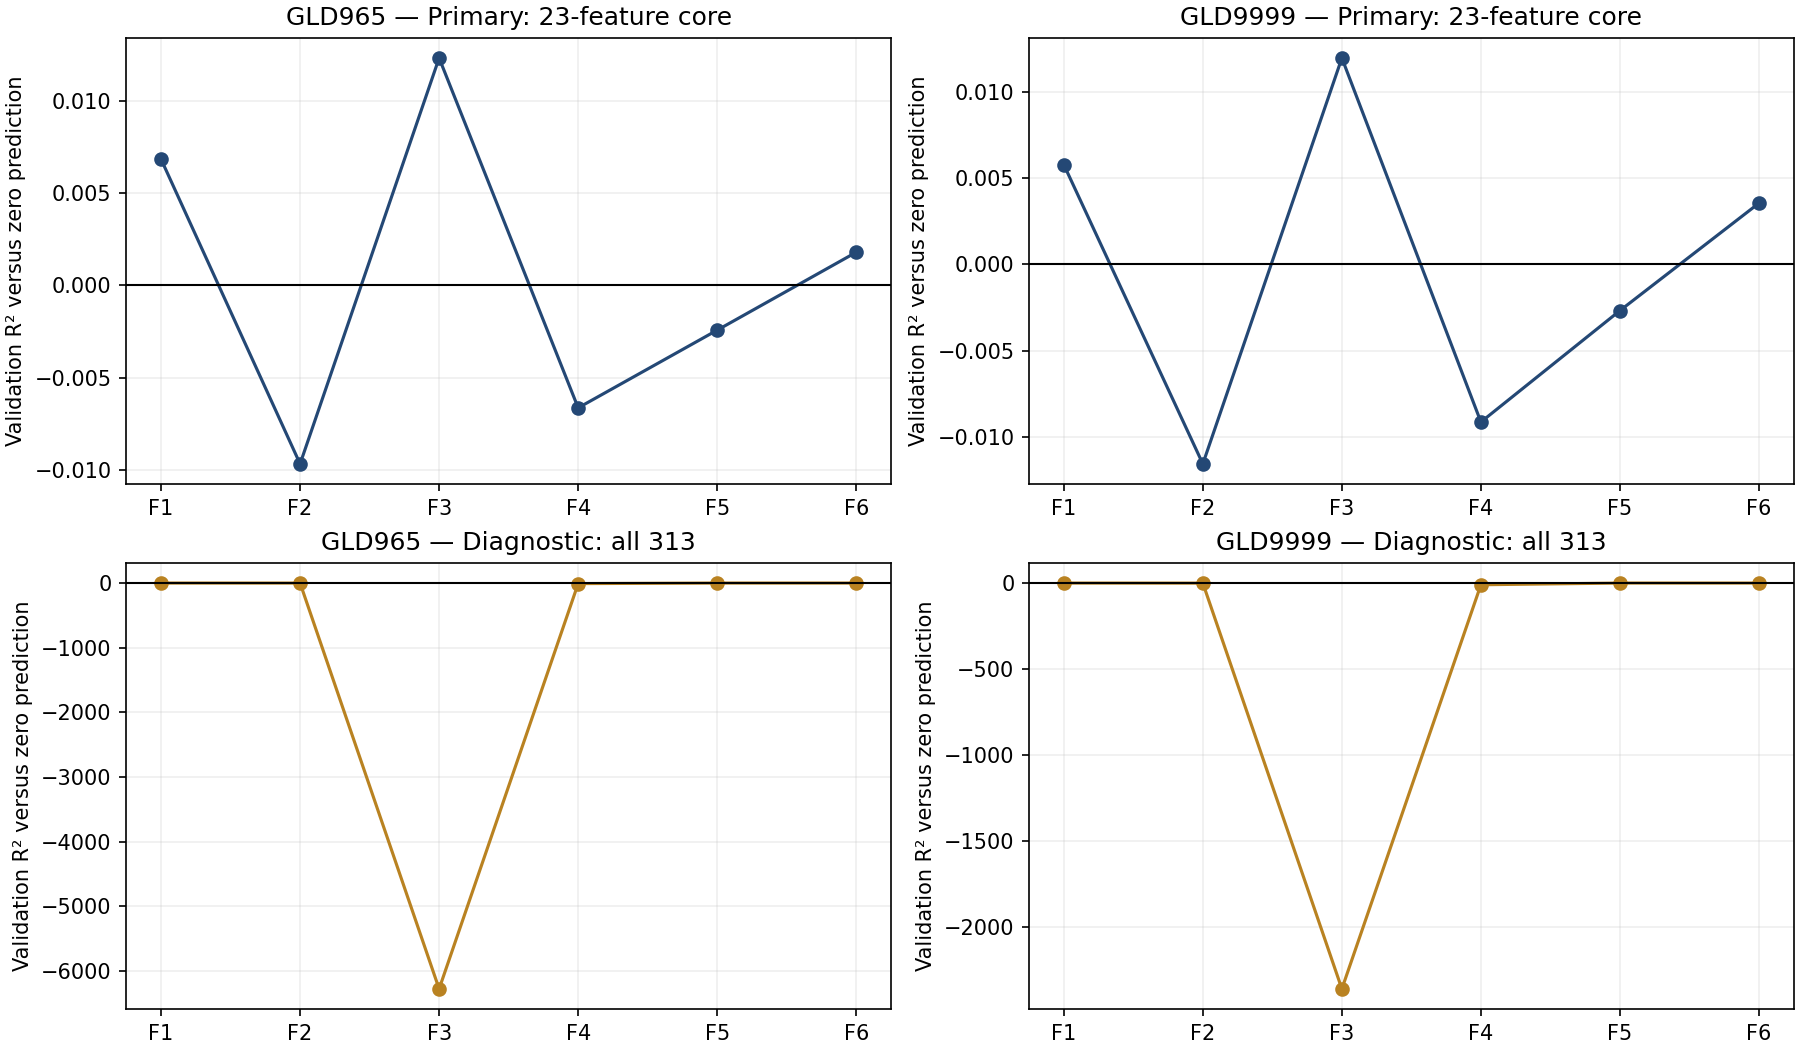

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'research/mts_gold/code').is_dir())
baseline = repo / 'research/mts_gold/training_artifacts/_training_baseline'
results = {p.stem: pd.read_csv(p) for p in (baseline / 'model1_results').glob('*.csv')}
ranges = results['extrapolation'].merge(
    results['coefficients'][['symbol', 'fold', 'model', 'feature', 'coefficient_standardized_x']],
    on=['symbol', 'fold', 'model', 'feature'], validate='one_to_one')
display(ranges.query("model == 'elasticnet_all313_diagnostic' and coefficient_standardized_x != 0").nlargest(12, 'max_abs_standardized_validation'))
display(results['worst_prediction_contributions'].query("model == 'elasticnet_all313_diagnostic' and fold == 'F3'"))
display(Image(filename=str(baseline / 'model1_results/fold_scores.png')))
